# Isochrony scores: most and least isochronous dyad clusters

The rhythm ratio of a dyad of durations `(d1, d2)` is `r = d1 / (d1 + d2)`, where 0.5 corresponds to perfect isochrony. We use `|r - 0.5|` as the non-isochrony score. This is the unnormalized version of the anisochrony score proposed in Cornelissen (2026), which is proportional to the nPVI (`metrics.cluster.non_isochrony`, stored as `centroid_non_isochrony` for each dyad cluster centroid).

Per bird and condition, we discard infrequent dyad clusters containing fewer than 5% of the dyads for that bird, and show the non-isochrony score of the most and least isochronous of the remaining clusters (`metrics.condition.bird_metrics`).

Each row uses annotated labels where available and predicted labels otherwise (RT, BWPS and BWPS-clean). Dashed lines show the shuffled baseline, in which labels are shuffled within each chunk.

In [1]:
import sys
sys.path.append('../src')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from viz.utils import set_mpl_style
set_mpl_style()

from pipeline.collect_metrics import load_bird_metrics

from viz.rows import row_height_ratios, clean_density_yaxis
from fig2_settings import SECTIONS, build_row_specs, PALETTE


In [2]:
# Per-bird scores of the most and least isochronous frequent pattern (see metrics.condition)
bird_summary = load_bird_metrics()

In [3]:
def isochrony_extremes(birds, datasets, rhythm_type, label_type='annot'):
    """Per bird, the non-isochrony score of its most and least isochronous frequent cluster."""
    subset = birds.query(
        'dataset_id in @datasets and rhythm_type == @rhythm_type and label_type == @label_type'
    )
    return subset['most_isochronous'], subset['least_isochronous']

In [4]:
SERIES_COLORS = dict(most=PALETTE[2], least=PALETTE[3])
SCORE_RANGE = (0, 0.5)
MIN_BINS, MAX_BINS = 8, 30

row_specs = build_row_specs(SECTIONS)
ROW_HEIGHT_RATIOS = row_height_ratios(row_specs)

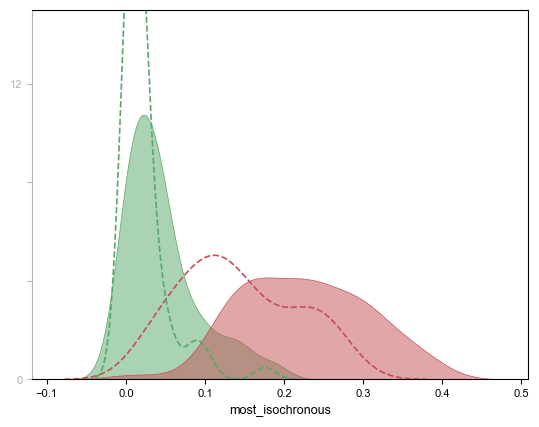

In [5]:
def plot_isochrony_ax(
        ax, datasets, rhythm_type, metrics, 
        colors=SERIES_COLORS, min_bins=MIN_BINS, max_bins=MAX_BINS
):
    if 'rt' in datasets or 'bwps' in datasets or 'bwps-clean' in datasets:
        label_type = 'pred'
    else:
        label_type = 'annot'

    # Annotated labels
    most, least = isochrony_extremes(metrics, datasets, rhythm_type, label_type=label_type)
    shared_kws = dict(fill=True, alpha=0.5, linewidth=.5, ax=ax, legend=False,)
    sns.kdeplot(x=most, color=colors['most'], **shared_kws)
    sns.kdeplot(x=least, color=colors['least'], **shared_kws)

    # Null: shuffled labels
    most_null, least_null = isochrony_extremes(metrics, datasets, rhythm_type, label_type='shuffle')
    null_kws = dict(linestyle="--", fill=False, linewidth=1.2, ax=ax, legend=False)
    sns.kdeplot(x=least_null, color=colors['least'], **null_kws)
    ymin, ymax = ax.get_ylim() # let the most isochronous not affect the ylims
    sns.kdeplot(x=most_null, color=colors['most'], **null_kws)
    ax.set_ylim(ymin*1.33, ymax*1.33)

    if label_type == 'pred':
        ax.annotate(
            'using predicted labels', xy=(1, 1), xycoords='axes fraction',
            ha='right', va='top', fontsize=7, style='italic', color='.4',
        )

    clean_density_yaxis(ax)
    return [
        plt.Rectangle((0, 0), 1, 1, color=colors['most'], alpha=0.4, label='Most isochronous pattern'),
        plt.Rectangle((0, 0), 1, 1, color=colors['least'], alpha=0.4, label='Least isochronous pattern'),
        plt.Line2D([0], [0], color='k', linestyle="--", lw=1, label='Shuffled labels'),
    ]

plot_isochrony_ax(plt.gca(), ['bvs', 'ns'], 'syll_dur', bird_summary)

In [6]:
def plot_isochrony_column(
    axes, row_specs, cluster, show_row_labels=True, legend=True,
    legend_loc='upper left', legend_bbox_to_anchor=(1.02, 1), legend_ax='first',
):
    handles, first_data_ax, last_data_ax = None, None, None
    for ax, (kind, row_label, spec) in zip(axes, row_specs):
        if kind == 'header':
            ax.axis('off')
            if show_row_labels:
                ax.text(0, 0.15, row_label, fontsize=8, fontweight='bold', transform=ax.transAxes, va='bottom')
            continue
        datasets, rhythm_type = spec
        row_handles = plot_isochrony_ax(ax, datasets, rhythm_type, cluster)
        handles = handles or row_handles
        first_data_ax = first_data_ax or ax
        last_data_ax = ax
        if show_row_labels:
            ax.set_ylabel(row_label, rotation=0, ha='right', va='center', fontsize=7)
    if legend and first_data_ax is not None:
        anchor_ax = first_data_ax if legend_ax == 'first' else last_data_ax
        anchor_ax.legend(handles=handles, loc=legend_loc, bbox_to_anchor=legend_bbox_to_anchor, fontsize=7, frameon=False)
    return axes

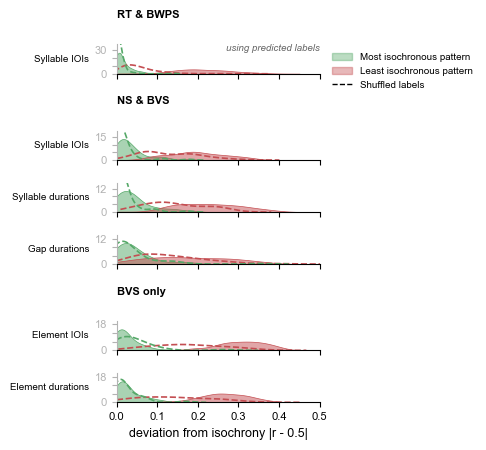

In [7]:
fig, axes = plt.subplots(
    len(row_specs), 1, figsize=(5, 0.5 * sum(ROW_HEIGHT_RATIOS) + 1),
    gridspec_kw=dict(height_ratios=ROW_HEIGHT_RATIOS), sharex=True,
)
plot_isochrony_column(axes, row_specs, bird_summary)

axes[-1].set_xlim(*SCORE_RANGE)
axes[-1].set_xlabel('deviation from isochrony |r - 0.5|')
sns.despine()
fig.tight_layout()